In [2]:
import pandas as pd
import yfinance as yf
#already run-once
# List of Indian stocks
stocks = ["TCS.NS", "INFY.NS", "RELIANCE.NS", "HDFCBANK.NS", "ITC.NS"]

all_data = []

print("Downloading stock data...\n")

for stock in stocks:
    print(f"Fetching {stock} ...")
    
    df = yf.download(
    stock,
    start="2020-01-01",
    end="2024-01-01",
    auto_adjust=True,
    group_by='column'
    )
    
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
        
    df.reset_index(inplace=True)
    df["Stock"] = stock
    
    all_data.append(df)

# Combine all stocks
final_data = pd.concat(all_data, ignore_index=True)

# Save raw data
final_data.to_csv("stock_data.csv", index=False)

print("\n✅ Multiple stock data saved successfully!")

# ----------------------------
# CLEAN TCS DATA FOR MODEL
# ----------------------------

data = final_data.copy()

# Filter only TCS
tcs = data[data["Stock"] == "TCS.NS"]

# Keep required columns
tcs = tcs[["Date","Open","High","Low","Close","Volume"]]

# Convert Date
tcs["Date"] = pd.to_datetime(tcs["Date"])

# Convert numeric safely
cols = ["Open","High","Low","Close","Volume"]

for col in cols:
    tcs[col] = pd.to_numeric(tcs[col], errors="coerce")

# Drop invalid rows
tcs.dropna(inplace=True)

# Sort by date (VERY IMPORTANT for stock data)
tcs = tcs.sort_values(by="Date")

# Save clean data
tcs.to_csv("TCS_clean.csv", index=False)

print("✅ Clean TCS data saved as TCS_clean.csv")


Fetching TCS.NS ...


[*********************100%***********************]  1 of 1 completed


Fetching INFY.NS ...


[*********************100%***********************]  1 of 1 completed


Fetching RELIANCE.NS ...


...

Fetching HDFCBANK.NS ...


[*********************100%***********************]  1 of 1 completed


Fetching ITC.NS ...


[*********************100%***********************]  1 of 1 completed


✅ Multiple stock data saved successfully!
✅ Clean TCS data saved as TCS_clean.csv


Loading clean stock data...

Training ML model...

✅ Model Training Complete!

MODEL PERFORMANCE
-------------------
Mean Absolute Error : ₹14.21
R2 Score           : 0.999

Actual vs Predicted:

   Actual Price  Predicted Price
0   2375.536133      2355.239322
1   2669.756836      2666.022983
2   3424.676025      3416.816385
3   2695.953369      2702.236888
4   1694.581055      1696.006182
5   3166.657715      3180.173342
6   2804.958984      2817.517275
7   1838.253784      1836.380270
8   1556.643433      1524.431797
9   3423.744873      3420.245402


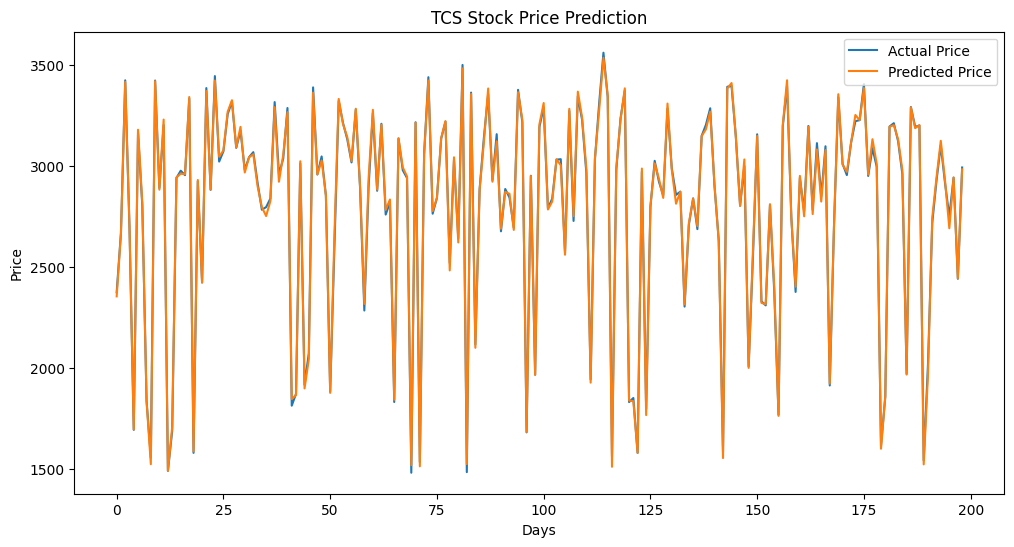


Predicting NEXT DAY price...

📈 Predicted Next Day Closing Price: ₹3533.18


C:\Users\ASUS\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

print("Loading clean stock data...\n")

df = pd.read_csv("TCS_clean.csv")

# FEATURES (Inputs)
X = df[["Open", "High", "Low", "Volume"]]

# TARGET
y = df["Close"]

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training ML model...\n")

# ⭐ Powerful Model
model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    random_state=42
)

model.fit(X_train, y_train)

print("✅ Model Training Complete!\n")

# Predictions
predictions = model.predict(X_test)

# -------------------
# Accuracy Check
# -------------------

mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("MODEL PERFORMANCE")
print("-------------------")
print(f"Mean Absolute Error : ₹{mae:.2f}")
print(f"R2 Score           : {r2:.3f}")

# -------------------
# Compare Prices
# -------------------

comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": predictions
})

print("\nActual vs Predicted:\n")
print(comparison.head(10))

# -------------------
# GRAPH (Faculty LOVE this)
# -------------------

plt.figure(figsize=(12,6))

plt.plot(y_test.values, label="Actual Price")
plt.plot(predictions, label="Predicted Price")

plt.title("TCS Stock Price Prediction")
plt.xlabel("Days")
plt.ylabel("Price")
plt.legend()

plt.show()

# -------------------
# 🔥 NEXT DAY PREDICTION
# -------------------

print("\nPredicting NEXT DAY price...\n")

latest_data = df.iloc[-1]

next_day_features = [[
    latest_data["Open"],
    latest_data["High"],
    latest_data["Low"],
    latest_data["Volume"]
]]

next_price = model.predict(next_day_features)

print(f"📈 Predicted Next Day Closing Price: ₹{next_price[0]:.2f}")